# Dari teks ulasan ke fitur aspek: ekstraksi ABSA dan empat representasi

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab03_sentiment_aware/01_absa_dan_representasi_aspek.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 3 · Kode 3.2.1 dan 3.3.1

**Tujuan belajar**

- Mengubah ulasan menjadi tabel kalimat–aspek dengan skor sentimen dan konfidens.
- Membandingkan empat cara merepresentasikan output ABSA sebagai fitur.
- Melihat mengapa rata-rata aspek dapat menghapus kontras polaritas.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> Klasifikator bintang di sini adalah **tiruan berbasis kamus kecil** (`star_logits_tiruan`), bukan model BERT. Ia ada agar pipeline bisa dijalankan tanpa mengunduh model. Angka yang keluar mirip pola pada Tabel 3.5, tetapi **tidak identik**.

## 1. Kode dari buku: ekstraksi (Kode 3.2.1)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax

LEXICON = {                      # contoh kamus restoran (bahasa Indonesia)
    "food": ["makan", "masakan", "rasa", "hidangan"],
    "service": ["pelayan", "layan", "staf"],
    "price": ["harga", "mahal", "murah"],
    "ambiance": ["suasana", "interior", "musik"],
}


def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]


def match_aspects(sentence, lexicon=LEXICON):
    """Langkah 1: sebuah kalimat cocok dengan aspek bila memuat salah satu stem."""
    s = sentence.lower()
    return [a for a, kws in lexicon.items() if any(kw in s for kw in kws)]


def extract(reviews, star_logits):
    """reviews: {review_id: teks}. star_logits(list[str]) -> array (n, 5).
    Mengembalikan satu baris per (kalimat, aspek) dengan skor di [0, 1]."""
    rows = [(rid, a, s) for rid, text in reviews.items()
            for s in split_sentences(text) for a in match_aspects(s)]
    df = pd.DataFrame(rows, columns=["review_id", "aspect", "sentence"])
    if df.empty:
        return df.assign(score=[], conf_softmax=[])
    z = np.asarray(star_logits(df["sentence"].tolist()))          # logit 5 kelas
    p = softmax(z, axis=1)
    y_hat = p @ np.arange(1, 6)               # bintang harapan, [1, 5]
    df["score"] = ((y_hat - 3) / 2 + 1) / 2   # skala bintang [1, 5] ke [0, 1]
    df["conf_softmax"] = p.max(axis=1)        # Pers. (3-2), bahan 3.4
    return df

Klasifikator tiruan: menilai kutub dari kata kunci, lalu menghasilkan logit 5 kelas berbentuk lonceng di sekitar bintang yang dituju. Kalimat tanpa petunjuk kutub mendapat sebaran lebar (tidak yakin), sehingga konfidens softmax-nya rendah.

In [2]:
POS = ["enak", "luar biasa", "lezat", "ramah", "cepat", "murah", "nyaman", "bagus", "segar"]
NEG = ["lambat", "cuek", "buruk", "mahal", "kotor", "bising", "hambar", "lama"]
NET = ["biasa"]

def star_logits_tiruan(sentences):
    """Logit lima kelas tiruan dari kamus kutub. Hanya untuk demonstrasi."""
    out = []
    for s in sentences:
        t = s.lower()
        pol = sum(w in t for w in POS) - sum(w in t for w in NEG)
        kuat = 1.25 if ("sangat" in t or "luar biasa" in t) else 1.0
        ada_petunjuk = pol != 0 or any(w in t for w in NET)
        target = 3 + 2 * float(np.clip(pol, -1, 1)) * 0.85 * kuat
        sigma = 0.7 if ada_petunjuk else 1.6          # tanpa petunjuk: tidak yakin
        out.append(-((np.arange(1, 6) - np.clip(target, 1, 5)) ** 2) / (2 * sigma ** 2))
    return np.array(out)

ulasan = {
    "A": "Makanannya luar biasa enak. Pelayanannya sangat lambat. Pelayannya cuek.",
    "B": "Makanannya biasa saja. Pelayanannya juga biasa.",
}
sent = extract(ulasan, star_logits_tiruan)
sent.round(3)

,review_id,aspect,sentence,score,conf_softmax
0,A,food,Makanannya luar biasa enak.,0.928,0.726
1,A,service,Pelayanannya sangat lambat.,0.072,0.726
2,A,service,Pelayannya cuek.,0.113,0.580
3,B,food,Makanannya biasa saja.,0.500,0.570
4,B,service,Pelayanannya juga biasa.,0.500,0.570


Satu baris per pasangan (kalimat, aspek). Ulasan A memiliki satu kalimat tentang makanan dan dua tentang layanan, dengan kutub yang saling berlawanan.

## 2. Kode dari buku: empat representasi (Kode 3.3.1)

In [3]:
FLOOR, EVID_CAP = 0.05, 3  # lantai konfidens, batas bukti (jumlah kalimat)


def per_aspect_table(sent, s0, aspects):
    """Rata-rata skor dan jumlah kalimat per (ulasan, aspek).
    Hasil: s (NaN bila aspek tidak disebut) dan n (0 bila tidak disebut)."""
    g = sent.groupby(["review_id", "aspect"])["score"].agg(s="mean", n="size")
    grid = dict(index=s0.index, columns=aspects)
    s = g["s"].unstack("aspect").reindex(**grid)
    n = g["n"].unstack("aspect").reindex(**grid).fillna(0)
    return s.to_numpy(), n.to_numpy()


def confidence(s, n):
    """Pers. (3-3): margin = |2s - 1|, bukti = min(n / 3, 1), lantai 0,05."""
    margin = np.abs(2 * s - 1)
    evidence = np.minimum(n / EVID_CAP, 1.0)
    return np.maximum((margin + evidence) / 2, FLOOR)


def mean_score(s_filled, hit, s0):
    """Strategi 1: rata-rata hanya atas aspek yang disebut, lainnya s0."""
    count = hit.sum(axis=1)
    total = np.where(hit, s_filled, 0.0).sum(axis=1)
    return np.where(count > 0, total / np.maximum(count, 1), s0)


def conf_weighted_mean(s_filled, c, hit, s0):
    """Strategi 2: rata-rata berbobot konfidens, hanya aspek yang disebut."""
    w = np.where(hit, c, 0.0)
    den = w.sum(axis=1)
    weighted = (w * s_filled).sum(axis=1) / np.maximum(den, 1e-12)
    return np.where(den > 0, weighted, s0)


def build_representations(sent, s0, aspects):
    """sent: DataFrame [review_id, aspect, score] (satu baris = satu kalimat).
    s0: skor fallback seluruh ulasan (indeks = review_id).
    Keempat representasi berbagi satu antarmuka, sehingga tahap fusi dapat
    ditahan tetap saat representasinya dibandingkan."""
    s, n = per_aspect_table(sent, s0, aspects)
    hit = ~np.isnan(s)
    s_filled = np.where(hit, s, s0.to_numpy()[:, None])  # Pers. (3-1): fallback
    c = confidence(s_filled, n)                          # n = 0: hanya margin

    def frame(values, prefix):
        cols = [f"{prefix}_{a}" for a in aspects]
        return pd.DataFrame(values, index=s0.index, columns=cols)

    s0v, idx = s0.to_numpy(), s0.index
    mean = mean_score(s_filled, hit, s0v)
    cmean = conf_weighted_mean(s_filled, c, hit, s0v)
    return {
        "mean": pd.DataFrame({"s_mean": mean}, index=idx),
        "conf_mean": pd.DataFrame({"s_confmean": cmean}, index=idx),
        "concat": frame(s_filled, "s"),
        "concat_conf": pd.concat([frame(s_filled, "s"), frame(c, "c")], axis=1),
    }

In [4]:
aspects = list(LEXICON)
# s0: skor seluruh ulasan (cadangan) = klasifikator pada teks utuh
z0 = softmax(star_logits_tiruan(list(ulasan.values())), axis=1)
s0 = pd.Series(((z0 @ np.arange(1, 6) - 3) / 2 + 1) / 2, index=list(ulasan), name="s0")
rep = build_representations(sent, s0, aspects)
for nama, df in rep.items():
    print("==", nama)
    print(df.round(2).to_string())

== mean
   s_mean
A    0.51
B    0.50
== conf_mean
   s_confmean
A        0.46
B        0.50
== concat
   s_food  s_service  s_price  s_ambiance
A    0.93       0.09      0.5         0.5
B    0.50       0.50      0.5         0.5
== concat_conf
   s_food  s_service  s_price  s_ambiance  c_food  c_service  c_price  c_ambiance
A    0.93       0.09      0.5         0.5    0.60       0.74     0.05        0.05
B    0.50       0.50      0.5         0.5    0.17       0.17     0.05        0.05


**Yang perlu dilihat.** Pada strategi *mean* dan *conf_mean*, ulasan A (makanan luar biasa, layanan buruk) dan B (semua biasa) berujung pada angka yang sama-sama dekat netral. *Concat* mempertahankan kontras: `s_food` A tinggi, `s_service` A rendah, sedangkan B datar. Kolom `c_price` dan `c_ambiance` kecil karena aspek itu tidak disebut.

In [5]:
A, B = rep["mean"].loc["A", "s_mean"], rep["mean"].loc["B", "s_mean"]
print(f"mean A = {A:.3f}, mean B = {B:.3f}, selisih = {abs(A - B):.3f}")
sA = rep["concat"].loc["A"]
assert sA["s_food"] - sA["s_service"] > 0.5            # kontras tetap ada pada concat
# aspek yang tidak disebut tidak pernah mendapat konfidens > 0,5 (hanya suku margin yang tersisa)
cc = rep["concat_conf"]
assert (cc.loc["A", ["c_price", "c_ambiance"]] <= 0.5).all()

mean A = 0.510, mean B = 0.500, selisih = 0.010


## 3. Eksperimen A: kontras polaritas runtuh

Bangkitkan 3.000 ulasan simulasi dengan skor aspek `food` dan `service` yang bebas satu sama lain. Kita ukur: pada ulasan yang aspeknya berlawanan, ke mana rata-rata jatuh?

ulasan dengan aspek berlawanan tajam: 5.0%
  rata-rata mereka berada di 0,35-0,65: 98.0%


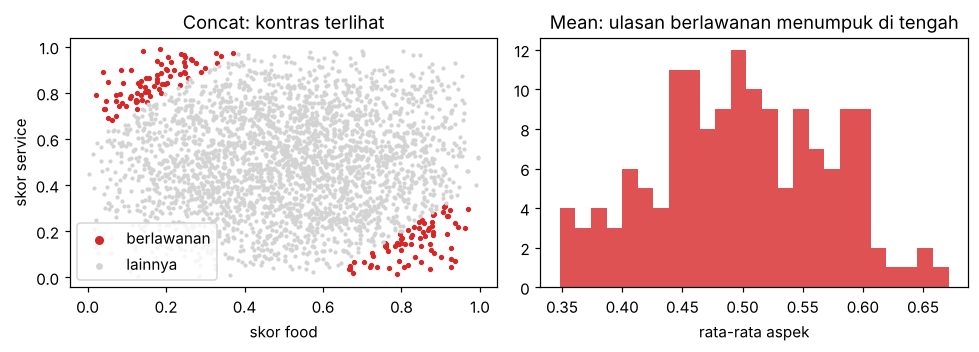

In [6]:
rng = np.random.default_rng(0)
n = 3000
food = rng.beta(2, 2, n)                    # skor aspek, di [0, 1]
service = rng.beta(2, 2, n)
rata2 = (food + service) / 2

kontras = np.abs(food - service) > 0.6      # aspek berlawanan tajam
print(f"ulasan dengan aspek berlawanan tajam: {100 * kontras.mean():.1f}%")
print(f"  rata-rata mereka berada di 0,35-0,65: {100 * ((rata2 > .35) & (rata2 < .65))[kontras].mean():.1f}%")

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.3))
a.scatter(food[kontras], service[kontras], s=6, c="tab:red", label="berlawanan")
a.scatter(food[~kontras], service[~kontras], s=3, c="lightgray", label="lainnya")
a.set(xlabel="skor food", ylabel="skor service", title="Concat: kontras terlihat")
a.legend(markerscale=2)
b.hist(rata2[kontras], bins=25, color="tab:red", alpha=.8)
b.set(xlabel="rata-rata aspek", title="Mean: ulasan berlawanan menumpuk di tengah")
fig.tight_layout()
assert ((rata2 > .35) & (rata2 < .65))[kontras].mean() > 0.6

**Interpretasi.** Pada ulasan yang aspeknya berlawanan tajam, rata-rata mayoritas jatuh di sekitar netral. Satu angka itu tidak dapat dibedakan dari ulasan yang benar-benar netral. Informasi yang hilang di tahap agregasi tidak bisa dikembalikan oleh model fusi sesudahnya. Inilah alasan buku menahan fusi tetap dan membandingkan *representasi*-nya.

## 4. Eksperimen B: "rata-rata" yang sebenarnya satu kalimat

Mekanisme kegagalan kedua pada buku: pada banyak ulasan hanya sedikit aspek yang disebut. Dengan peluang menyebut tiap aspek *p*, berapa persen ulasan yang "rata-ratanya" tersusun dari tidak lebih dari satu aspek?

In [7]:
rng = np.random.default_rng(1)
rows = []
for p in (0.2, 0.35, 0.5, 0.7):
    disebut = rng.random((20000, 4)) < p
    k = disebut.sum(axis=1)
    rows.append({"p_sebut_aspek": p, "0 aspek_%": 100 * (k == 0).mean(),
                 "1 aspek_%": 100 * (k == 1).mean(), ">=2 aspek_%": 100 * (k >= 2).mean()})
tabel = pd.DataFrame(rows).set_index("p_sebut_aspek")
print(tabel.round(1))
assert tabel.loc[0.35, "0 aspek_%"] + tabel.loc[0.35, "1 aspek_%"] > 50

               0 aspek_%  1 aspek_%  >=2 aspek_%
p_sebut_aspek                                   
0.20                41.1       40.9         18.0
0.35                17.7       38.8         43.6
0.50                 6.0       24.8         69.2
0.70                 0.8        7.4         91.9


**Interpretasi (simulasi).** Jika setiap aspek hanya disebut dengan peluang sekitar sepertiga, lebih dari separuh ulasan menyebut satu aspek atau tidak sama sekali. Untuk ulasan itu, "rata-rata multi-aspek" adalah skor satu kalimat, atau cadangan `s0`. Ia bukan ringkasan beberapa aspek. Menurut buku, inilah yang menyuntikkan derau pada dua varian agregasi.

## Pertanyaan refleksi

1. Mengapa konfidens aspek yang tidak disebut tidak pernah melebihi 0,5 pada Persamaan (3-3)? Apa gunanya bagi model hilir?
2. Kalimat tanpa kata kutub mendapat konfidens softmax rendah di klasifikator tiruan. Apa yang terjadi bila klasifikator sungguhan *overconfident* pada kalimat seperti itu?
3. Ubah `LEXICON` ke domain hotel. Apa yang berubah pada tabel kalimat–aspek, dan apa yang tidak?